# Signal Generator Examples

## Initial Setup
Import the signal generator class from `inspy.instrument.signalgenerator`. Two instruments are used in this notebook: the signal generator (AWG) under test, and an oscilloscope, which is used purely to visually verify the AWG's output. Device connections can be managed by using the `connect()` and `disconnect()` methods. However, the use of context managers is recommended.

In [1]:
import numpy as np
from IPython.display import Image

from inspy.instrument.oscilloscope import OscilloscopeKeysightDSOX1202G
from inspy.instrument.signalgenerator import SigGenAgilent33220A

siggen = SigGenAgilent33220A("USB0::2391::1031::MY44030903::INSTR")
siggen.connect()

scope = OscilloscopeKeysightDSOX1202G("USB0::10893::919::CN61444220::INSTR")
scope.connect()

# Get the ID of the instruments
print("ID of the instruments:")
print(f"Signal Generator: {siggen.get_id()}")
print(f"Oscilloscope: {scope.get_id()}")

ID of the instruments:
Signal Generator: Agilent Technologies,33220A,MY44030903,2.07-2.06-22-2
Oscilloscope: KEYSIGHT TECHNOLOGIES,DSOX1202G,CN61444220,02.11.2020062221


## Configuring Waveforms
Various waveforms can be configured on the signal generator, ranging from a simple Sine wave to a custom user-defined waveform.

### Sine Wave

In [2]:
siggen.set_impedance("HIGH")
siggen.set_waveform_mode("SINE")
siggen.set_frequency(1_000)
siggen.set_voltage_amplitude(6.0)
siggen.set_voltage_offset(0.0)
siggen.set_channel_state(True)

print(f"Mode: {siggen.get_waveform_mode()}")
print(f"Frequency: {siggen.get_frequency():.0f} Hz")

Mode: SINE
Frequency: 1000 Hz


#### Sine Wave Output
The signal generator's output was connected to channel 1 on an oscilloscope, with the time base and voltage range changed accordingly:

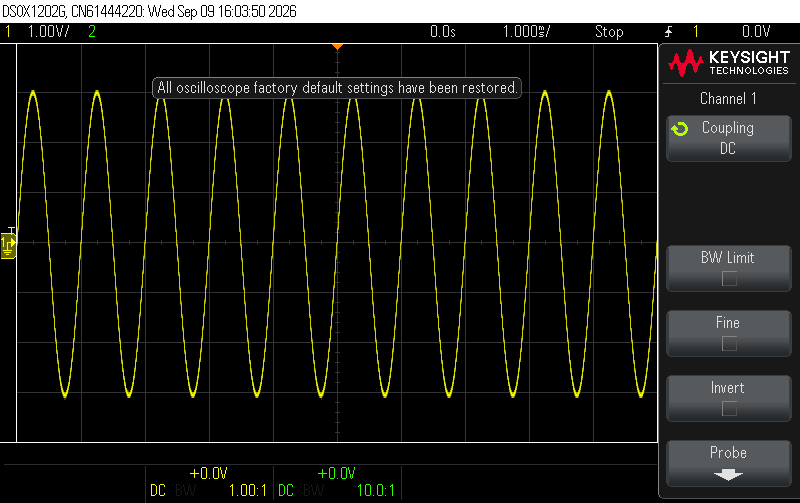

In [3]:
scope.reset()
scope.set_timebase(timebase_range=10e-3)
scope.set_channel(channel=1, voltage_range=8.0, attenuation=1.0)
scope.set_trigger(channel=1, level=0.0, slope="POS", sweep="NORM")
scope.digitize()
Image(scope.get_screenshot())

### Square Wave with Output Impedance

In [4]:
siggen.set_waveform_mode("SQUARE")
siggen.set_frequency(500)
siggen.set_impedance("HIGH")
siggen.set_voltage_amplitude(2.0)
siggen.set_voltage_offset(0.0)
siggen.set_channel_state(True)

print(f"Mode: {siggen.get_waveform_mode()}")
print(f"Output impedance: {siggen.get_impedance()} ohm")

Mode: SQUARE
Output impedance: HIGH ohm


#### Square Wave Output
The signal generator's output was connected to channel 1 on an oscilloscope, with the time base and voltage range changed accordingly:

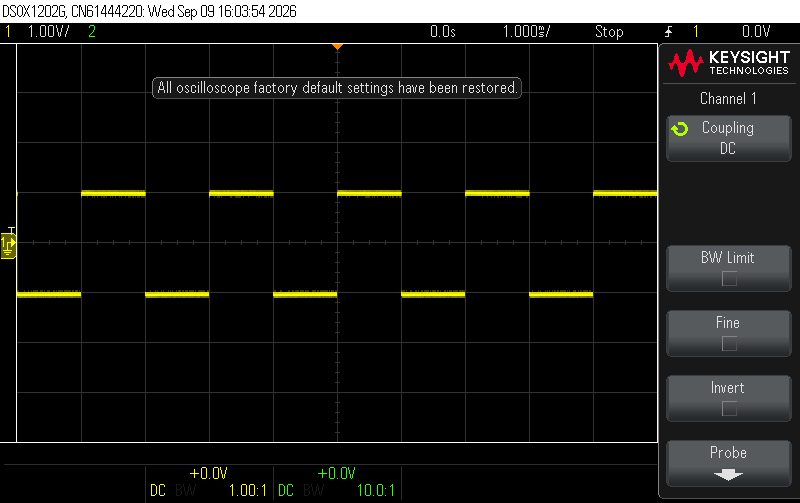

In [5]:
scope.reset()
scope.set_timebase(timebase_range=10e-3)
scope.set_channel(channel=1, voltage_range=8.0, attenuation=1.0)
scope.set_trigger(channel=1, level=0.0, slope="POS", sweep="NORM")
scope.digitize()
Image(scope.get_screenshot())

### Custom Waveform

In [6]:
# Build a custom shape: values must be in [-1.0, 1.0]
t = np.arange(200) / 200
samples = 0.5 * (1 - np.cos(2 * np.pi * t)) * np.sin(2 * np.pi * 8 * t)

# Clean up the saved custom waveform from previous attempts
siggen.delete_saved_user_waveform("custom")

# Upload, save, set mode to USER and enable channel
siggen.set_new_arbitrary_waveform(samples, name="custom")
print(f"Saved waveforms: {siggen.get_saved_user_waveforms()}")

# Re-select if switching away and back
siggen.set_saved_user_waveform("custom")
siggen.set_frequency(200)
siggen.set_voltage_amplitude(4.0)

Saved waveforms: ['CUSTOM']


#### Custom Waveform Output
The signal generator's output was connected to channel 1 on an oscilloscope, with the time base and voltage range changed accordingly:

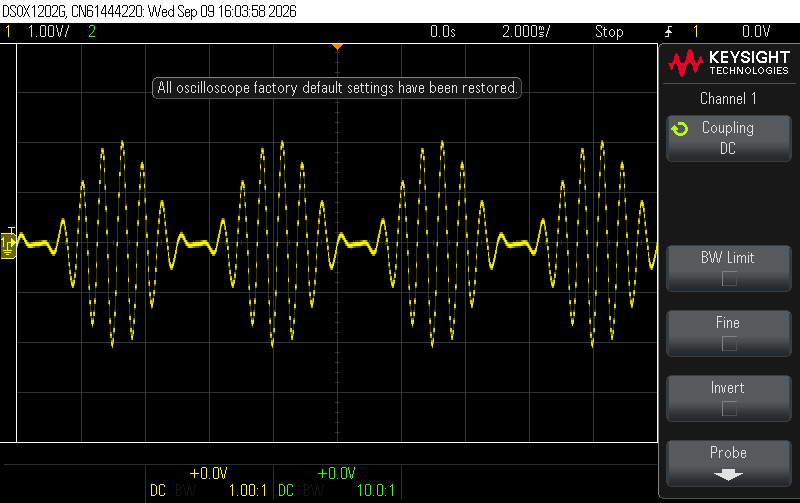

In [7]:
scope.reset()
scope.set_timebase(timebase_range=20e-3)
scope.set_channel(channel=1, voltage_range=8.0, attenuation=1.0)
scope.set_trigger(channel=1, level=0.0, slope="POS", sweep="NORM")
scope.digitize()
Image(scope.get_screenshot())

In [8]:
# Once finished, disconnect the instruments
siggen.disconnect()
scope.disconnect()